# Atividade Guiada: AG com PyGAD para Seleção de Características em Classificação Wine.ipynb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 kB 4.6 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/pygad/utils/validation.py:1287: UserWarning: Both keep_parents (=2) and keep_elitism (=1) are set. Because keep_elitism is greater than 0, it takes precedence and keep_parents is ignored. To make keep_parents take effect, set keep_elitism=0.
  warnings.warn(f"Both keep_parents (={self.keep_parents}) and keep_elitism (={self.keep_elitism}) are set. Because keep_elitism is greater than 0, it takes precedence and keep_parents is ignored. To make keep_parents take effect, set keep_elitism=0.")


Executando o Algoritmo Genético para seleção de características do dataset Wine...

Características selecionadas (índices): [1, 2, 3, 7, 9, 10, 11, 12]
Número de características selecionadas: 8
Acurácia CV estimada (penalizada): 0.9863
Características selecionadas (nomes):
1. malic_acid
2. ash
3. alcalinity_of_ash
4. nonflavanoid_phenols
5. color_intensity
6. hue
7. od280/od315_of_diluted_wines
8. proline


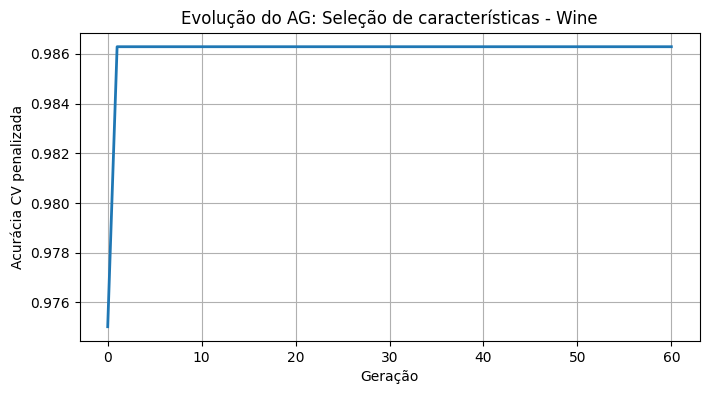


Acurácia final (5-fold CV): 0.9943 +/- 0.0114 
Scores: [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(0.9714), np.float64(1.0)]


In [ ]:
# @title Atividade: Seleção de Características com AG (PyGAD) - Dataset Wine
# Objetivo: Usar Algoritmo Genético para selecionar subconjuntos de variáveis otimizando a acurácia de classificação

# Instalação das bibliotecas necessárias
!pip -q install pygad scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import pygad

# Importando utilitários de machine learning
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------------------------
# 1. Configuração de Semente
# ------------------------------------------------------------------------------
np.random.seed(7)  # Para garantir que os resultados sejam iguais em todas execuções

# ------------------------------------------------------------------------------
# 2. Carregamento e Preparação dos Dados
# ------------------------------------------------------------------------------
data = load_wine()
X_raw, y = data.data, data.target

scaler = StandardScaler()             # Normaliza dados para média 0 e variância 1
X = scaler.fit_transform(X_raw)       # Fundamental para melhor performance em LR

n_features = X.shape[1]  # 13 genes: cada gene representa uma feature; 1 = seleciona, 0 = ignora

# ------------------------------------------------------------------------------
# 3. Função de Avaliação para Subconjunto de Features
# ------------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)  # Mantém proporção das classes
clf = LogisticRegression(max_iter=200, solver="liblinear")

def evaluate_subset(mask):
    """
    Dada uma máscara binária, calcula acurácia do classificador usando apenas as features selecionadas.
    Aplica penalização leve pelo número de features (para priorizar soluções simples).
    """
    if mask.sum() == 0:        # Garante que ao menos 1 feature seja usada
        return 0.0
    X_sel = X[:, mask.astype(bool)]                        # Seleciona features com mask
    scores = cross_val_score(clf, X_sel, y, cv=cv, scoring="accuracy")  # Validação cruzada
    penalty = 0.001 * mask.sum()    # Penaliza soluções com muitas features
    return float(scores.mean() - penalty)

# ------------------------------------------------------------------------------
# 4. Função de Fitness para PyGAD
# ------------------------------------------------------------------------------
def fitness_func(ga, solution, sol_idx):
    """
    Recebe o cromossomo do AG (array), converte para máscara binária, e retorna avaliação/fitness.
    """
    mask = (np.array(solution) > 0.5).astype(int)  # Threshold: float para binário
    return evaluate_subset(mask)

# ------------------------------------------------------------------------------
# 5. Configuração do Algoritmo Genético
# ------------------------------------------------------------------------------
ga = pygad.GA(
    num_generations=60,                # Quantidade de ciclos evolutivos
    sol_per_pop=40,                    # Tamanho da população inicial
    num_parents_mating=20,             # Quantidade de pais por geração (promove recombinação)
    num_genes=n_features,              # Cada cromossomo tem 13 genes
    init_range_low=0,                  # Inicialização dos genes para [0, 1]
    init_range_high=1,
    gene_space=[0, 1],                 # Genes binários {0,1}
    fitness_func=fitness_func,
    parent_selection_type="sss",        # Steady-state selection (equilibra elitismo e variedade)
    crossover_type="single_point",      # Crossover de um ponto para transição de genes entre pais
    mutation_type="random",             # Mutação aleatória típica dos AGs
    mutation_percent_genes=20,          # Porcentagem dos genes mutáveis a cada geração
    keep_parents=2,                     # Elitismo: garante preservação dos dois melhores indivíduos
    random_seed=7                       # Reprodutível!
)

print("Executando o Algoritmo Genético para seleção de características do dataset Wine...")
ga.run()                # Processo evolutivo inicia: otimização dos subconjuntos de variáveis

# ------------------------------------------------------------------------------
# 6. Extração e Exibição dos Resultados
# ------------------------------------------------------------------------------
best_solution, best_fitness, _ = ga.best_solution()
best_mask = (np.array(best_solution) > 0.5).astype(int)    # Mask: indica as features mantidas
selected = np.where(best_mask == 1)[0].tolist()            # Lista com índices das features selecionadas
selected_names = [data.feature_names[i] for i in selected] # Lista de nomes das features selecionadas

print("\nCaracterísticas selecionadas (índices):", selected)
print("Número de características selecionadas:", len(selected))
print("Acurácia CV estimada (penalizada):", round(best_fitness, 4))
print("Características selecionadas (nomes):")
for i, name in enumerate(selected_names, 1):
    print(f"{i}. {name}")

# ------------------------------------------------------------------------------
# 7. Visualização da Evolução do Fitness ao longo das gerações
# ------------------------------------------------------------------------------
history = np.array(ga.best_solutions_fitness)
plt.figure(figsize=(8,4))
plt.plot(history, linewidth=2)
plt.xlabel("Geração")
plt.ylabel("Acurácia CV penalizada")
plt.title("Evolução do AG: Seleção de características - Wine")
plt.grid(True)
plt.show()

# ------------------------------------------------------------------------------
# 8. Validação Cruzada Final com o Subconjunto Ótimo encontrado
# ------------------------------------------------------------------------------
if len(selected) > 0:
    X_sel = X[:, selected]
    final_scores = cross_val_score(clf, X_sel, y, cv=cv, scoring="accuracy")
    print("\nAcurácia final (5-fold CV):", round(final_scores.mean(), 4),
          "+/-", round(final_scores.std(), 4),
          "\nScores:", [round(s,4) for s in final_scores])
else:
    print("Nenhuma feature selecionada. Avalie os parâmetros do AG.")

# ------------------------------------------------------------------------------
# Dicas finais:
# ------------------------------------------------------------------------------
# - Teste diferentes configurações e observe impactos no gráfico de evolução
# - Tente alterar penalização no fitness para entender relação entre simplicidade e performance
# - Compare resultados com baseline (todas as features)
# - Troque para outro dataset/classificador e refaça análise para outros cenários



# *Orientações (resumo das anotações):*

* *Gene e Cromossomo*: Cada gene = característica. Cromossomo = subconjunto de características candidato.

* População: Vários subconjuntos competem e evoluem em busca da melhor combinação.

* *Fitness*: Mede acurácia média do modelo e penaliza excesso de variáveis.

* *Seleção*: "Steady-state" mantém diversidade e evolução estável.

* *Crossover & Mutação*: Mistura genes entre pais; faz pequenos ajustes aleatórios para explorar possibilidades.

* *Elitismo*: Garante que as melhores soluções não sejam perdidas no processo evolutivo.

* *Análise dos Resultados*: Observe o gráfico para identificar convergência ou necessidade de ajustes.

* *Validação Final*: Confere se as features selecionadas realmente melhoram ou mantêm desempenho comparado ao modelo com todas as variáveis.

# Orientações
* Execute todo o código proposto.

* Observe atentamente as saídas, interpretando quais variáveis foram selecionadas e como evoluiu o fitness.

* Responda às perguntas do questionário baseando-se nos experimentos realizados e nos conceitos estudados sobre AG.

* Se surgirem dúvidas, retome os principais pontos da aula sobre codificação de soluções, fitness e operadores genéticos.